<a href="https://colab.research.google.com/github/khushi-eng/DMV/blob/main/QAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
pip install qiskit qiskit_aer  pylatexenc qiskit qiskit-aer -q qiskit-ibm-runtime

In [42]:

# Practical 1: Creation and Execution of a Quantum Circuit

from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_aer import AerSimulator

# 1. Create Quantum Register with 16 qubits
q = QuantumRegister(16, 'q')

# 2. Create Classical Register with 16 bits
c = ClassicalRegister(16, 'c')

# 3. Create Quantum Circuit
circuit = QuantumCircuit(q, c)

# 4. Apply Hadamard gate to all qubits
circuit.h(q)

# 5. Measure all qubits
circuit.measure(q, c)

# Display the circuit
print("Quantum Circuit:")
print(circuit.draw())

# 6. Create simulator backend
backend = AerSimulator()

# 7. Execute the circuit with 1 shot
job = backend.run(circuit, shots=1)

print("\nExecuting Job...\n")

# 8. Get the result
result = job.result()

# 9. Get measurement counts
counts = result.get_counts(circuit)

print("RESULT:", counts)

print("\nPress any key to close")
input()


Quantum Circuit:
      ┌───┐┌─┐                                             
 q_0: ┤ H ├┤M├─────────────────────────────────────────────
      ├───┤└╥┘┌─┐                                          
 q_1: ┤ H ├─╫─┤M├──────────────────────────────────────────
      ├───┤ ║ └╥┘┌─┐                                       
 q_2: ┤ H ├─╫──╫─┤M├───────────────────────────────────────
      ├───┤ ║  ║ └╥┘┌─┐                                    
 q_3: ┤ H ├─╫──╫──╫─┤M├────────────────────────────────────
      ├───┤ ║  ║  ║ └╥┘┌─┐                                 
 q_4: ┤ H ├─╫──╫──╫──╫─┤M├─────────────────────────────────
      ├───┤ ║  ║  ║  ║ └╥┘┌─┐                              
 q_5: ┤ H ├─╫──╫──╫──╫──╫─┤M├──────────────────────────────
      ├───┤ ║  ║  ║  ║  ║ └╥┘┌─┐                           
 q_6: ┤ H ├─╫──╫──╫──╫──╫──╫─┤M├───────────────────────────
      ├───┤ ║  ║  ║  ║  ║  ║ └╥┘┌─┐                        
 q_7: ┤ H ├─╫──╫──╫──╫──╫──╫──╫─┤M├────────────────────────
      ├───┤ ║  ║  ║  ║ 

'h'

In [43]:

# Practical 2: Tackle Noise with Error Correction
# 3-Qubit Bit-Flip Error Correction

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# 1. Create 3 data qubits
q = QuantumRegister(3, 'q')

# 2. Create 2 classical bits for error syndrome
c = ClassicalRegister(2, 'c')

# 3. Create quantum circuit
circuit = QuantumCircuit(q, c)

# 4. Prepare original quantum information
# Here we prepare the state |1>
circuit.x(q[0])

# 5. Encoding: Spread information across 3 qubits
circuit.cx(q[0], q[1])
circuit.cx(q[0], q[2])

# 6. Introduce noise (bit-flip error)
# Here we intentionally flip the second qubit
circuit.x(q[1])

# 7. Error detection using parity checks
circuit.cx(q[0], q[1])
circuit.cx(q[0], q[2])

# Measure syndrome
circuit.measure(q[1], c[0])
circuit.measure(q[2], c[1])

# 8. Correct the error based on syndrome
with circuit.if_test((c[0], 1)):
    circuit.x(q[0])

# Display circuit
print("Quantum Error Correction Circuit:")
print(circuit.draw())

# 9. Create simulator
backend = AerSimulator()

# 10. Execute circuit
job = backend.run(circuit, shots=1024)

# 11. Get results
result = job.result()
counts = result.get_counts()

print("\nError Syndrome Results:")
print(counts)


Quantum Error Correction Circuit:
     ┌───┐                                 ┌──────  ┌───┐ ───────┐ 
q_0: ┤ X ├──■────■─────────■────■──────────┤ If-0  ─┤ X ├  End-0 ├─
     └───┘┌─┴─┐  │  ┌───┐┌─┴─┐  │  ┌─┐     └──╥───  └───┘ ───────┘ 
q_1: ─────┤ X ├──┼──┤ X ├┤ X ├──┼──┤M├────────╫────────────────────
          └───┘┌─┴─┐└───┘└───┘┌─┴─┐└╥┘┌─┐     ║                    
q_2: ──────────┤ X ├──────────┤ X ├─╫─┤M├─────╫────────────────────
               └───┘          └───┘ ║ └╥┘┌────╨────┐               
c: 2/═══════════════════════════════╩══╩═╡ c_0=0x1 ╞═══════════════
                                    0  1 └─────────┘               

Error Syndrome Results:
{'01': 1024}


Libraries imported successfully.
Initial State:
[2, 5, 3]
[1, 8, 6]
[4, 7, None]

Goal State:
[1, 2, 3]
[4, 5, 6]
[7, 8, None]
9-Qubit quantum circuit created successfully.
Initial puzzle state encoded.
Quantum operations applied successfully.
All qubits measured successfully.
     ┌───┐ ░ ┌───┐           ░ ┌─┐                        
q_0: ┤ X ├─░─┤ H ├──■────────░─┤M├────────────────────────
     ├───┤ ░ ├───┤┌─┴─┐      ░ └╥┘┌─┐                     
q_1: ┤ X ├─░─┤ H ├┤ X ├──■───░──╫─┤M├─────────────────────
     ├───┤ ░ ├───┤└───┘┌─┴─┐ ░  ║ └╥┘┌─┐                  
q_2: ┤ X ├─░─┤ H ├─────┤ X ├─░──╫──╫─┤M├──────────────────
     ├───┤ ░ ├───┤     └───┘ ░  ║  ║ └╥┘┌─┐               
q_3: ┤ X ├─░─┤ H ├──■────────░──╫──╫──╫─┤M├───────────────
     ├───┤ ░ ├───┤┌─┴─┐      ░  ║  ║  ║ └╥┘┌─┐            
q_4: ┤ X ├─░─┤ H ├┤ X ├──■───░──╫──╫──╫──╫─┤M├────────────
     ├───┤ ░ ├───┤└───┘┌─┴─┐ ░  ║  ║  ║  ║ └╥┘┌─┐         
q_5: ┤ X ├─░─┤ H ├─────┤ X ├─░──╫──╫──╫──╫──╫─┤M├─────────
     ├───┤ ░ ├

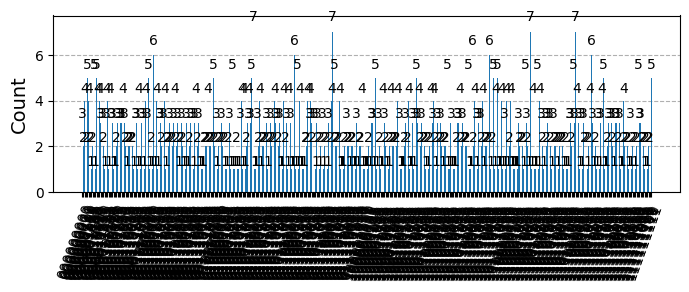

In [44]:

# Practical 3: Implementing Tarrataca's Quantum Production System
# with the 3-Puzzle Problem

# 1. Import libraries

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

print("Libraries imported successfully.")


# 2. Define initial and goal states

initial_state = [2, 5, 3,
                 1, 8, 6,
                 4, 7, None]

goal_state = [1, 2, 3,
              4, 5, 6,
              7, 8, None]


# 3. Display initial and goal states

print("Initial State:")
print(initial_state[:3])
print(initial_state[3:6])
print(initial_state[6:])

print("\nGoal State:")
print(goal_state[:3])
print(goal_state[3:6])
print(goal_state[6:])


# 4. Create a 9-qubit quantum circuit

qc = QuantumCircuit(9, 9)

print("9-Qubit quantum circuit created successfully.")


# 5. Encode the initial puzzle state

for i, tile in enumerate(initial_state):

    if tile is not None:
        qc.x(i)

qc.barrier()

print("Initial puzzle state encoded.")


# 6. Apply quantum operations

qc.h(0)
qc.h(1)
qc.h(2)

qc.cx(0, 1)
qc.cx(1, 2)


qc.h(3)
qc.h(4)
qc.h(5)

qc.cx(3, 4)
qc.cx(4, 5)


qc.h(6)
qc.h(7)
qc.h(8)

qc.cx(6, 7)
qc.cx(7, 8)

qc.barrier()

print("Quantum operations applied successfully.")


# 7. Measure all qubits

qc.measure(range(9), range(9))

print("All qubits measured successfully.")


# 8. Display quantum circuit

print(qc.draw())


# 9. Simulate the quantum circuit

simulator = AerSimulator()

compiled_qc = transpile(qc, simulator)

job = simulator.run(compiled_qc, shots=1024)

result = job.result()

counts = result.get_counts()

print("Simulation completed successfully.")

print("\nMeasurement Results:")
print(counts)


# 10. Find the most probable quantum state

solution = max(counts, key=counts.get)

print("\nMost probable quantum state:")
print(solution)

print("\nNumber of occurrences:")
print(counts[solution])


# 11. Display measurement histogram

fig = plot_histogram(counts, figsize=(7, 3))

display(fig)


In [45]:

# Practical 4: Quantum Teleportation Algorithm

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from math import pi

# 1. Create 3 qubits
q = QuantumRegister(3, 'q')

# 2. Create 2 classical bits
c = ClassicalRegister(2, 'c')

# 3. Create quantum circuit
circuit = QuantumCircuit(q, c)

# 4. Prepare Alice's original quantum state
circuit.ry(pi/3, q[0])

# 5. Create entanglement between Alice and Bob
circuit.h(q[1])
circuit.cx(q[1], q[2])

# 6. Alice performs CNOT
circuit.cx(q[0], q[1])

# 7. Alice applies Hadamard gate
circuit.h(q[0])

# 8. Alice measures her two qubits
circuit.measure(q[0], c[0])
circuit.measure(q[1], c[1])

# 9. Bob applies correction gates
with circuit.if_test((c[1], 1)):
    circuit.x(q[2])

with circuit.if_test((c[0], 1)):
    circuit.z(q[2])

# 10. Display circuit
print("Quantum Teleportation Circuit:")
print(circuit.draw())

# 11. Create simulator
backend = AerSimulator()

# 12. Execute circuit
job = backend.run(circuit, shots=1024)

# 13. Get results
result = job.result()
counts = result.get_counts()

print("\nMeasurement Results:")
print(counts)


Quantum Teleportation Circuit:
     ┌─────────┐          ┌───┐┌─┐                                          »
q_0: ┤ Ry(π/3) ├───────■──┤ H ├┤M├──────────────────────────────────────────»
     └──┬───┬──┘     ┌─┴─┐└┬─┬┘└╥┘                                          »
q_1: ───┤ H ├─────■──┤ X ├─┤M├──╫───────────────────────────────────────────»
        └───┘   ┌─┴─┐└───┘ └╥┘  ║   ┌──────  ┌───┐ ───────┐   ┌──────  ┌───┐»
q_2: ───────────┤ X ├───────╫───╫───┤ If-0  ─┤ X ├  End-0 ├───┤ If-0  ─┤ Z ├»
                └───┘       ║   ║   └──╥───  └───┘ ───────┘   └──╥───  └───┘»
                            ║   ║ ┌────╨────┐               ┌────╨────┐     »
c: 2/═══════════════════════╩═══╩═╡ c_1=0x1 ╞═══════════════╡ c_0=0x1 ╞═════»
                            1   0 └─────────┘               └─────────┘     »
«               
«q_0: ──────────
«               
«q_1: ──────────
«      ───────┐ 
«q_2:   End-0 ├─
«      ───────┘ 
«c: 2/══════════
«               

Measurement Results:
{'01': 267, '1

5-Qubit Quantum Circuit Created Successfully.
Input state 10101 encoded successfully.
5-Qubit Quantum Fourier Transform applied successfully.
All 5 qubits measured successfully.
     ┌───┐┌───┐ ░ ┌──────┐┌─┐            
q_0: ┤ X ├┤ X ├─░─┤0     ├┤M├────────────
     └───┘└───┘ ░ │      │└╥┘┌─┐         
q_1: ───────────░─┤1     ├─╫─┤M├─────────
     ┌───┐┌───┐ ░ │      │ ║ └╥┘┌─┐      
q_2: ┤ X ├┤ X ├─░─┤2 QFT ├─╫──╫─┤M├──────
     └───┘└───┘ ░ │      │ ║  ║ └╥┘┌─┐   
q_3: ───────────░─┤3     ├─╫──╫──╫─┤M├───
     ┌───┐┌───┐ ░ │      │ ║  ║  ║ └╥┘┌─┐
q_4: ┤ X ├┤ X ├─░─┤4     ├─╫──╫──╫──╫─┤M├
     └───┘└───┘ ░ └──────┘ ║  ║  ║  ║ └╥┘
c: 5/══════════════════════╩══╩══╩══╩══╩═
                           0  1  2  3  4 

QFT Simulation Completed.

QFT Output:
{'10001': 25, '01001': 25, '10101': 20, '11110': 38, '00010': 31, '10010': 41, '11100': 30, '00110': 35, '00001': 33, '00101': 35, '11010': 34, '11000': 23, '01111': 34, '01011': 26, '11101': 31, '00111': 40, '00011': 38, '11111': 30, '

/tmp/ipykernel_2940/3261594606.py:38: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(


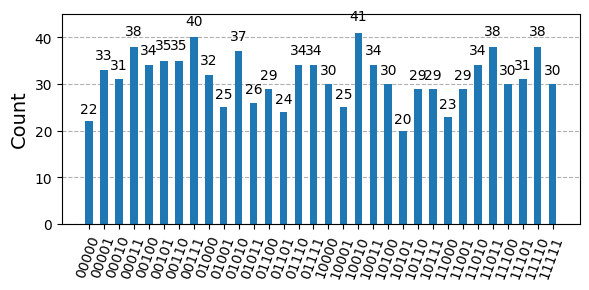

In [46]:

# Practical 5: Implementing a 5-Qubit Quantum Fourier Transform

# 1. Import libraries

from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import QFT
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

# 2. Create quantum and classical registers

q = QuantumRegister(5, 'q')
c = ClassicalRegister(5, 'c')

circuit = QuantumCircuit(q, c)

print("5-Qubit Quantum Circuit Created Successfully.")


# 3. Encode input state 10101

circuit.x(q[4])
circuit.x(q[2])
circuit.x(q[0])

circuit.x(q[4])
circuit.x(q[2])
circuit.x(q[0])

circuit.barrier()

print("Input state 10101 encoded successfully.")


# 4. Apply 5-Qubit Quantum Fourier Transform

qft = QFT(
    num_qubits=5,
    approximation_degree=0,
    do_swaps=True,
    inverse=False,
    insert_barriers=True,
    name='QFT'
)

circuit.compose(qft, qubits=q, inplace=True)

print("5-Qubit Quantum Fourier Transform applied successfully.")


# 5. Measure all 5 qubits

circuit.measure(q, c)

print("All 5 qubits measured successfully.")


# 6. Display quantum circuit

print(circuit.draw())


# 7. Decompose QFT into basic gates

circuit = circuit.decompose(reps=5)


# 8. Run the circuit using simulator

simulator = AerSimulator()

job = simulator.run(circuit, shots=1000)

result = job.result()

counts = result.get_counts()

print("\nQFT Simulation Completed.")

print("\nQFT Output:")
print(counts)


# 9. Display measurement histogram

fig = plot_histogram(counts, figsize=(6, 3))

display(fig)
